In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

rng = np.random.default_rng(42)

x1 = rng.normal(0, 2, 50)
x2 = 0.1 * x1 + rng.normal(0, 0.6, 50)

X = np.column_stack([x1, x2])

In [2]:
pca = PCA()
pca.fit(X)

print(pca.explained_variance_ratio_)

[0.91916501 0.08083499]


In [3]:
pca = PCA(n_components=1)
X_pca = pca.fit_transform(X)
X_back = pca.inverse_transform(X_pca)

print(np.mean((X - X_back) ** 2))

0.1026341004623067


In [4]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine()

X = wine.data

X = StandardScaler().fit_transform(X)

In [5]:
pca = PCA()
pca.fit(X)

print(pca.explained_variance_ratio_.cumsum())

[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


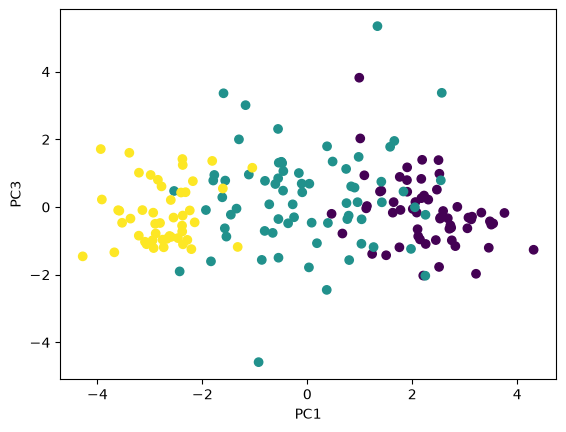

In [6]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

y = wine.target

plt.scatter(X_pca[:, 0], X_pca[:, 2], c=y)
plt.xlabel("PC1")
plt.ylabel("PC3")
plt.show()

In [7]:
print(wine.feature_names)
print(pca.components_[1])

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
[ 0.48365155  0.22493093  0.31606881 -0.0105905   0.299634    0.06503951
 -0.00335981  0.02877949  0.03930172  0.52999567 -0.27923515 -0.16449619
  0.36490283]


In [8]:
weights = pca.components_[1]

for i in np.argsort(np.abs(weights))[-3:]:
    print(wine.feature_names[i], weights[i])

proline 0.36490283179808203
alcohol 0.48365154781721403
color_intensity 0.5299956720700434
